In [23]:
import numpy as np
import matplotlib.pyplot as plt
from random import randint
from pathlib import Path

PROJECT_ROOT = next(
    candidate
    for directory in (Path.cwd(), *Path.cwd().parents)
    for candidate in (directory, directory / "EI-DATA-DRIVEN-CONTROL")
    if (candidate / "src/model/checkpoints/rnn_z.onnx").is_file()
)
DATA_DIR = PROJECT_ROOT / "data/generated_data"
CHECKPOINT_DIR = PROJECT_ROOT / "src/model/checkpoints"
for filename in ("rnn_input_z.csv", "rnn_output_z.csv"):
    if not (DATA_DIR / filename).is_file():
        raise FileNotFoundError(f"Supply the original training dataset at {DATA_DIR / filename}")

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader

device = "cuda" if torch.cuda.is_available() else "cpu"

def normalize(input_array):
    min_val = np.min(input_array)
    max_val = np.max(input_array)
    
    return (input_array - min_val) / (max_val - min_val)

def standardize(input_array):
    return (input_array - np.mean(input_array)) / np.std(input_array)
def mimic_standardize(input_array, mimic_mean, mimic_std):
    return (input_array - mimic_mean) / mimic_std

# data import

data_in = np.genfromtxt(DATA_DIR / "rnn_input_z.csv", delimiter=",", dtype=np.float32)[:, :1000]
data_out = np.genfromtxt(DATA_DIR / "rnn_output_z.csv", delimiter=",", dtype=np.float32)[:, :3000]
nb_data = data_in.shape[0]


In [24]:
train_size = int(0.7*nb_data)
val_size = int(0.15*nb_data)
test_size = int(0.15*nb_data)

az_data = mimic_standardize(data_out[:, 2::3], -9.68746566772461, 21.440523147583008)
input_data = mimic_standardize(data_in, -0.004098882433027029, 1.7267645597457886)

In [25]:
import onnx
import onnxruntime

onnx_model = onnx.load(CHECKPOINT_DIR / "rnn_z.onnx")
onnx.checker.check_model(onnx_model)

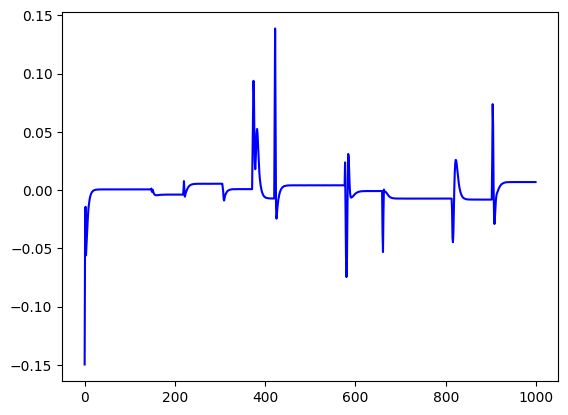

In [28]:
onnx_model = onnx.load(CHECKPOINT_DIR / "rnn_z.onnx")
onnx.checker.check_model(onnx_model)

ort_session = onnxruntime.InferenceSession(
    str(CHECKPOINT_DIR / "rnn_z.onnx"), providers=["CPUExecutionProvider"]
)

input_names = [inp.name for inp in ort_session.get_inputs()]
x_name = input_names[0]
h_name = input_names[1]

train_rand_idx = randint(0, train_size-1)
test_rand_idx = randint(train_size+val_size, nb_data-1)

full_sequence = input_data[test_rand_idx].reshape(1, 1000, 1).astype(np.float32)

hidden_size = 32
h = np.zeros((1, 1, hidden_size), dtype=np.float32)

onnxruntime_outputs_list = []

for t in range(full_sequence.shape[1]):
    x_step = full_sequence[:, t:t+1, :]
    
    out, h = ort_session.run(
        None, 
        {x_name: x_step, h_name: h}
    )
    onnxruntime_outputs_list.append(out)

onnxruntime_outputs = np.concatenate(onnxruntime_outputs_list, axis=1)

#plt.plot(input_data[test_rand_idx].reshape(1000), c="blue")
#plt.plot(az_data[test_rand_idx], c="green")
#plt.plot(onnxruntime_outputs[:, :][0], c="red")
plt.plot(az_data[test_rand_idx] - onnxruntime_outputs[:, :][0][:, 0], c="blue")